In [1]:
import sys
from pathlib import Path

project_path = Path("..").resolve()
sys.path.append(str(project_path))

import numpy as np
import matplotlib.pyplot as plt
from src.inference.predict import load_model
from src.models.unet_3d_monai import UNet3D_MONAI
import torch



In [3]:
project_root = Path("/mnt/x/segmentation_cfos")
model_path = project_root / "outputs" / "checkpoints" / "best_model.pth"
device = "cuda" if torch.cuda.is_available() else "cpu"

model = load_model(model_path, UNet3D_MONAI, device, init_features=32)
print(f"Modèle chargé sur {device}")

✅ Modèle chargé depuis: /mnt/x/segmentation_cfos/outputs/checkpoints/best_model.pth
   Époque: 44
   Score: 0.299487
Modèle chargé sur cuda


In [4]:
pred_dir = project_root / "outputs" / "evaluation" / "predictions"
pred_files = sorted(pred_dir.glob("*.npz"))

print(f"Nombre d'échantillons: {len(pred_files)}")
print(f"Premiers fichiers: {[f.name for f in pred_files[:5]]}")



Nombre d'échantillons: 20
Premiers fichiers: ['sample_0000.npz', 'sample_0001.npz', 'sample_0002.npz', 'sample_0003.npz', 'sample_0004.npz']


In [5]:
def visualize_prediction(sample_data, sample_name, slice_index=None):
    """
    Visualise image, mask réel et mask prédit
    """
    image = sample_data["image"]
    mask = sample_data["mask"]
    prediction = sample_data["prediction"]
    
    if slice_index is None:
        slice_index = image.shape[0] // 2

    img_slice = image[slice_index, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()

    pred_bin = (prediction[slice_index, :, :] > 0.5).astype(np.float32)
    mask_slice = mask[slice_index, :, :]
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes[0, 0].imshow(img_slice, cmap='gray')
    axes[0, 0].set_title(f'Image - Slice {slice_index}')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(mask_slice, cmap='gray')
    axes[0, 1].set_title(f'Mask Réel - {np.sum(mask_slice)} voxels')
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(pred_bin, cmap='gray')
    axes[0, 2].set_title(f'Mask Prédit - {np.sum(pred_bin)} voxels')
    axes[0, 2].axis('off')
    
    overlay1 = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay1[mask_slice > 0, 0] = 0
    overlay1[mask_slice > 0, 1] = 1
    overlay1[mask_slice > 0, 2] = 0
    axes[1, 0].imshow(overlay1)
    axes[1, 0].set_title('Image + Mask Réel (vert)')
    axes[1, 0].axis('off')
    overlay2 = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay2[pred_bin > 0, 0] = 1
    overlay2[pred_bin > 0, 1] = 0
    overlay2[pred_bin > 0, 2] = 0
    axes[1, 1].imshow(overlay2)
    axes[1, 1].set_title('Image + Prédiction (rouge)')
    axes[1, 1].axis('off')
    overlay3 = np.stack([img_slice, img_slice, img_slice], axis=-1)
    tp = (mask_slice > 0) & (pred_bin > 0)
    overlay3[tp, 0] = 0
    overlay3[tp, 1] = 1
    overlay3[tp, 2] = 0
    fp = (mask_slice == 0) & (pred_bin > 0)
    overlay3[fp, 0] = 1
    overlay3[fp, 1] = 0
    overlay3[fp, 2] = 0
    fn = (mask_slice > 0) & (pred_bin == 0)
    overlay3[fn, 0] = 0
    overlay3[fn, 1] = 0
    overlay3[fn, 2] = 1
    axes[1, 2].imshow(overlay3)
    axes[1, 2].set_title('Comparaison (vert=TP, rouge=FP, bleu=FN)')
    axes[1, 2].axis('off')
    
    plt.suptitle(f'Échantillon: {sample_name} | Slice {slice_index}')
    plt.tight_layout()
    plt.show()
    print(f"Statistiques de l'échantillon {sample_name}:")
    print(f"  Voxels dans l'image: {image.size:,}")
    print(f"  Voxels neurones (réel): {mask.sum():,}")
    print(f"  Voxels neurones (prédit): {prediction[prediction > 0.5].size:,}")
    print(f"  Taux de détection: {prediction[prediction > 0.5].size / mask.sum() if mask.sum() > 0 else 0:.2f}x")




Échantillon 1: sample_0000


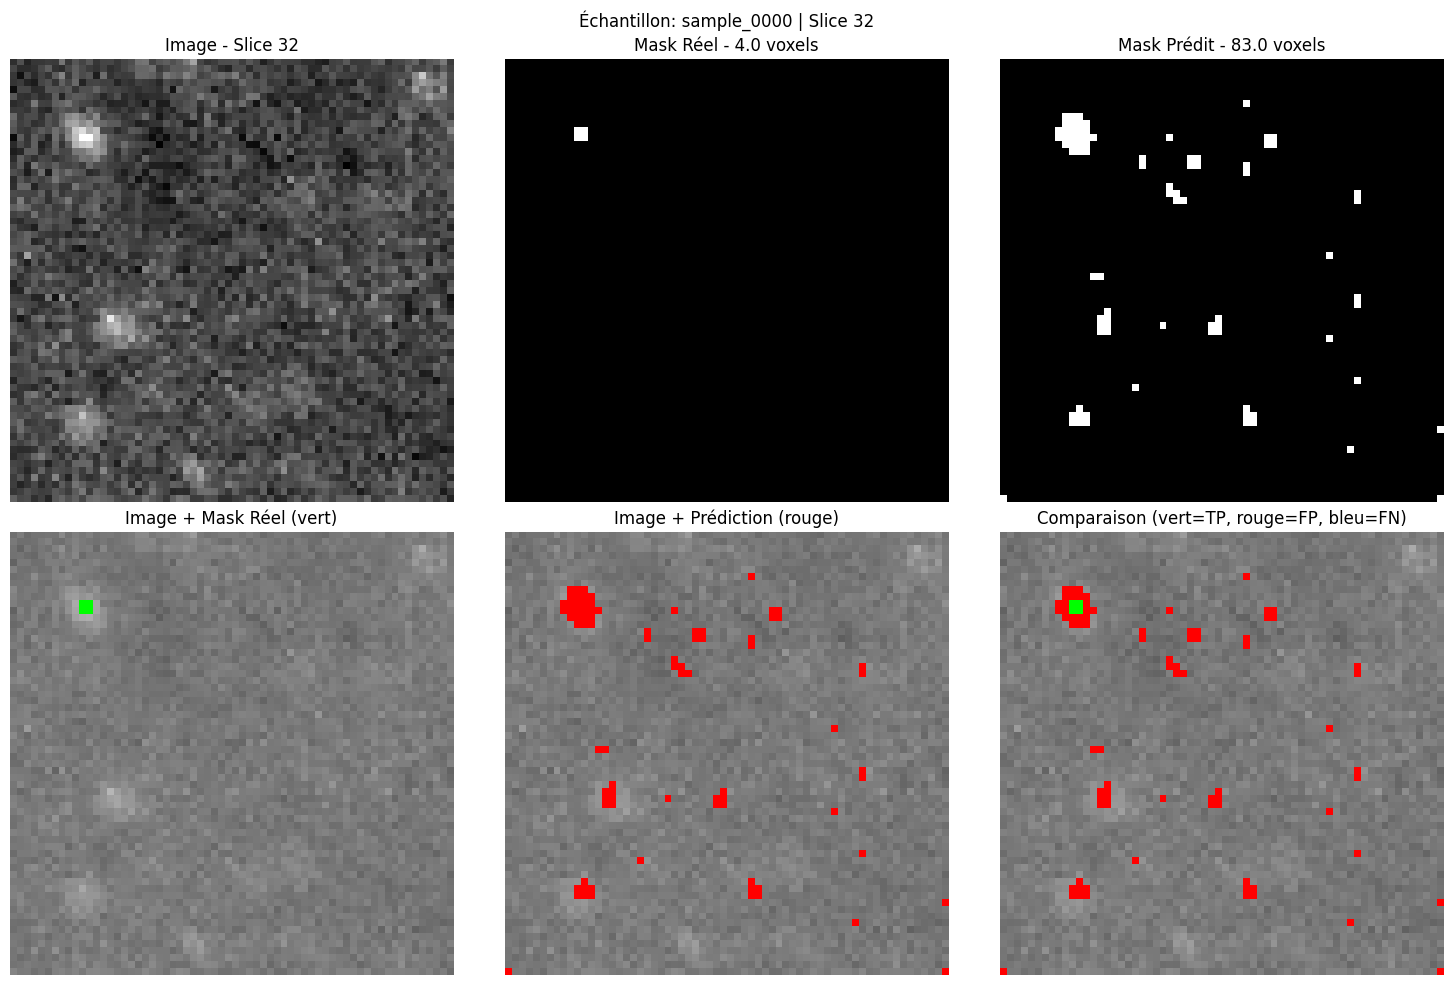

Statistiques de l'échantillon sample_0000:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 242.0
  Voxels neurones (prédit): 14,586
  Taux de détection: 60.27x

Échantillon 2: sample_0001


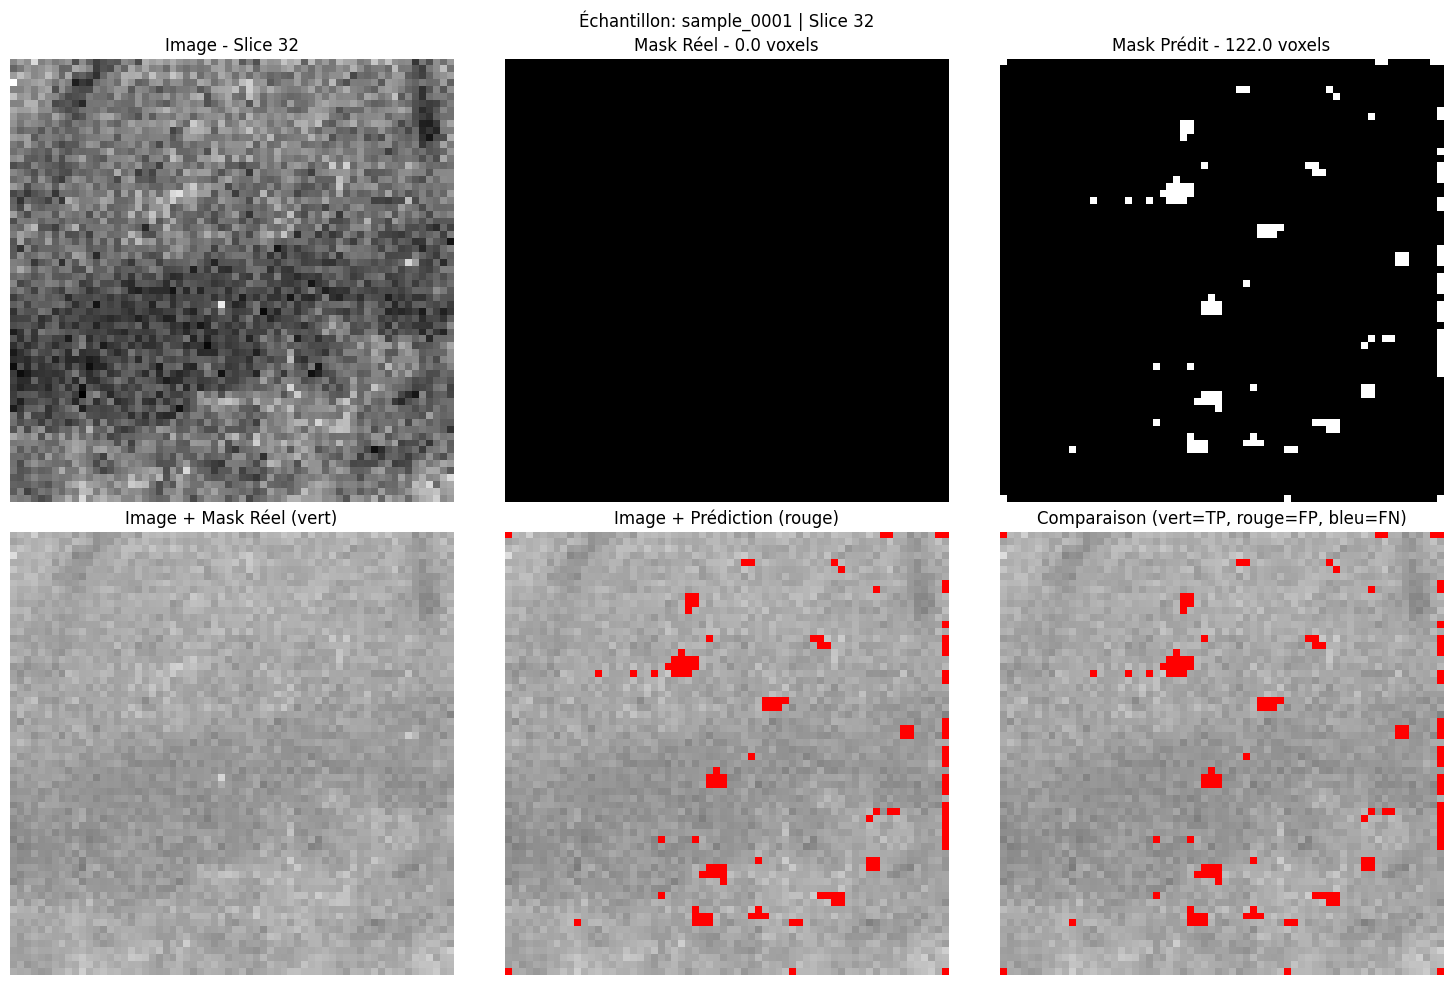

Statistiques de l'échantillon sample_0001:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 9.0
  Voxels neurones (prédit): 17,808
  Taux de détection: 1978.67x

Échantillon 3: sample_0002


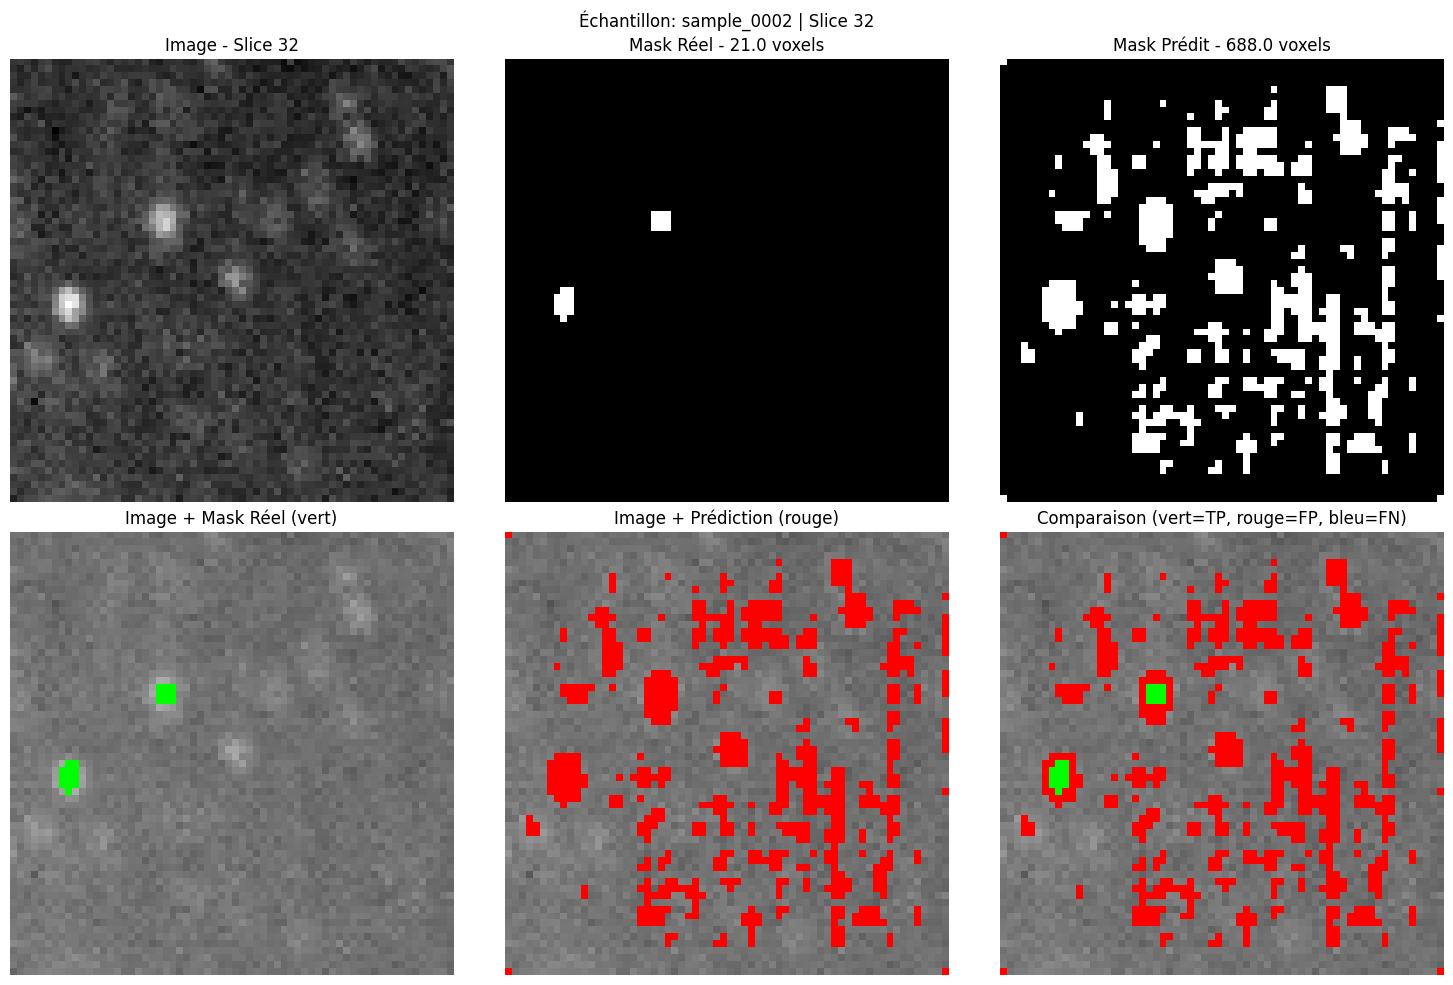

Statistiques de l'échantillon sample_0002:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 277.0
  Voxels neurones (prédit): 19,821
  Taux de détection: 71.56x

Échantillon 4: sample_0003


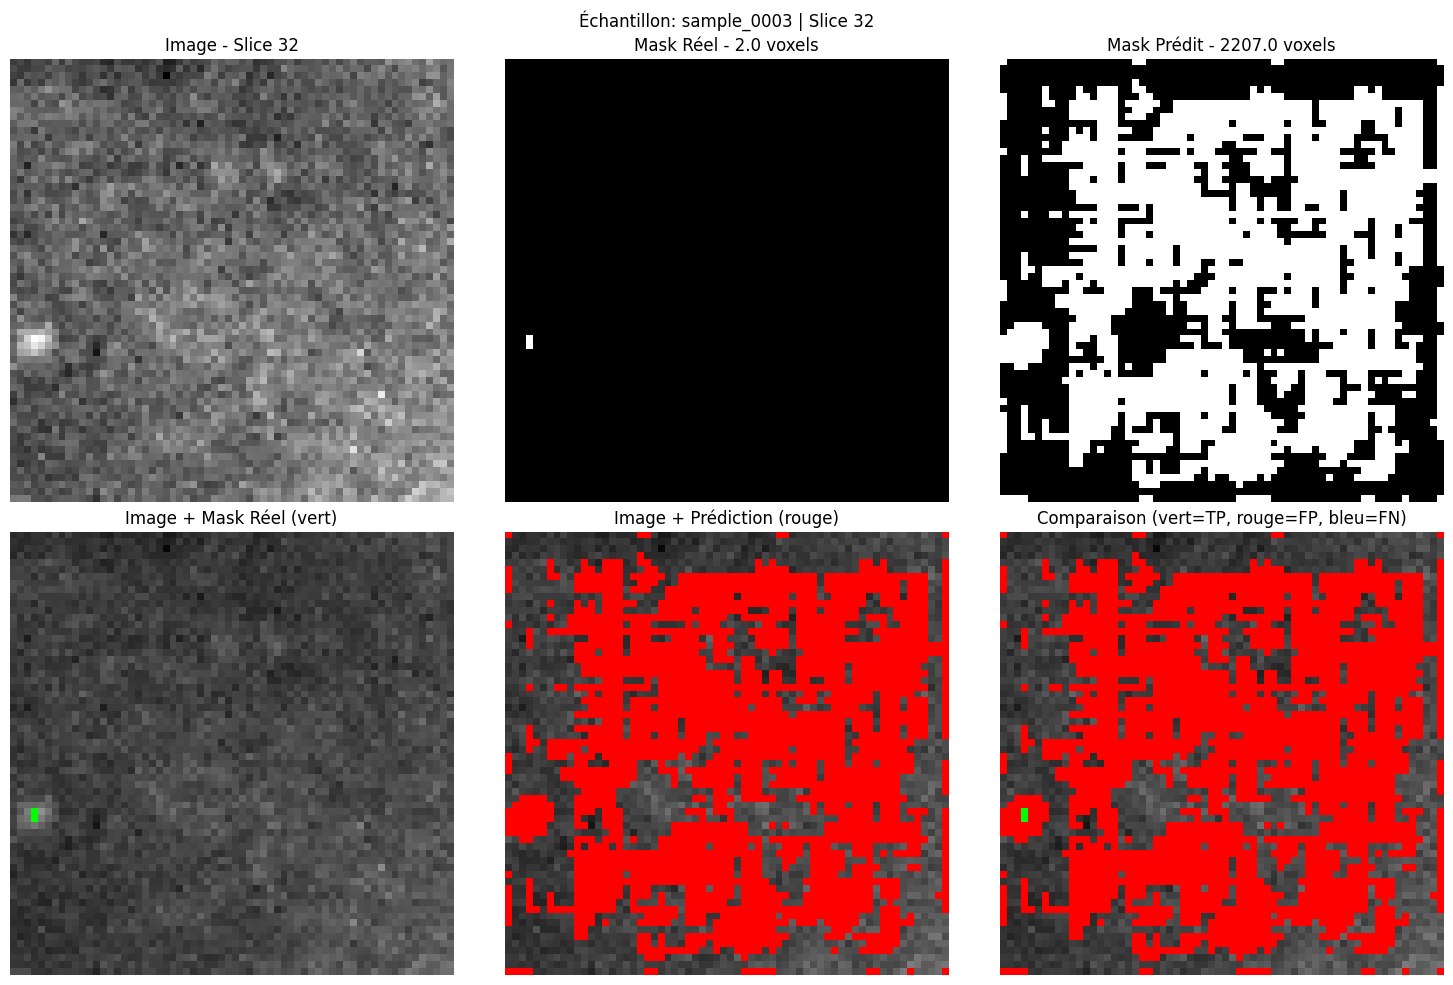

Statistiques de l'échantillon sample_0003:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 217.0
  Voxels neurones (prédit): 104,125
  Taux de détection: 479.84x

Échantillon 5: sample_0004


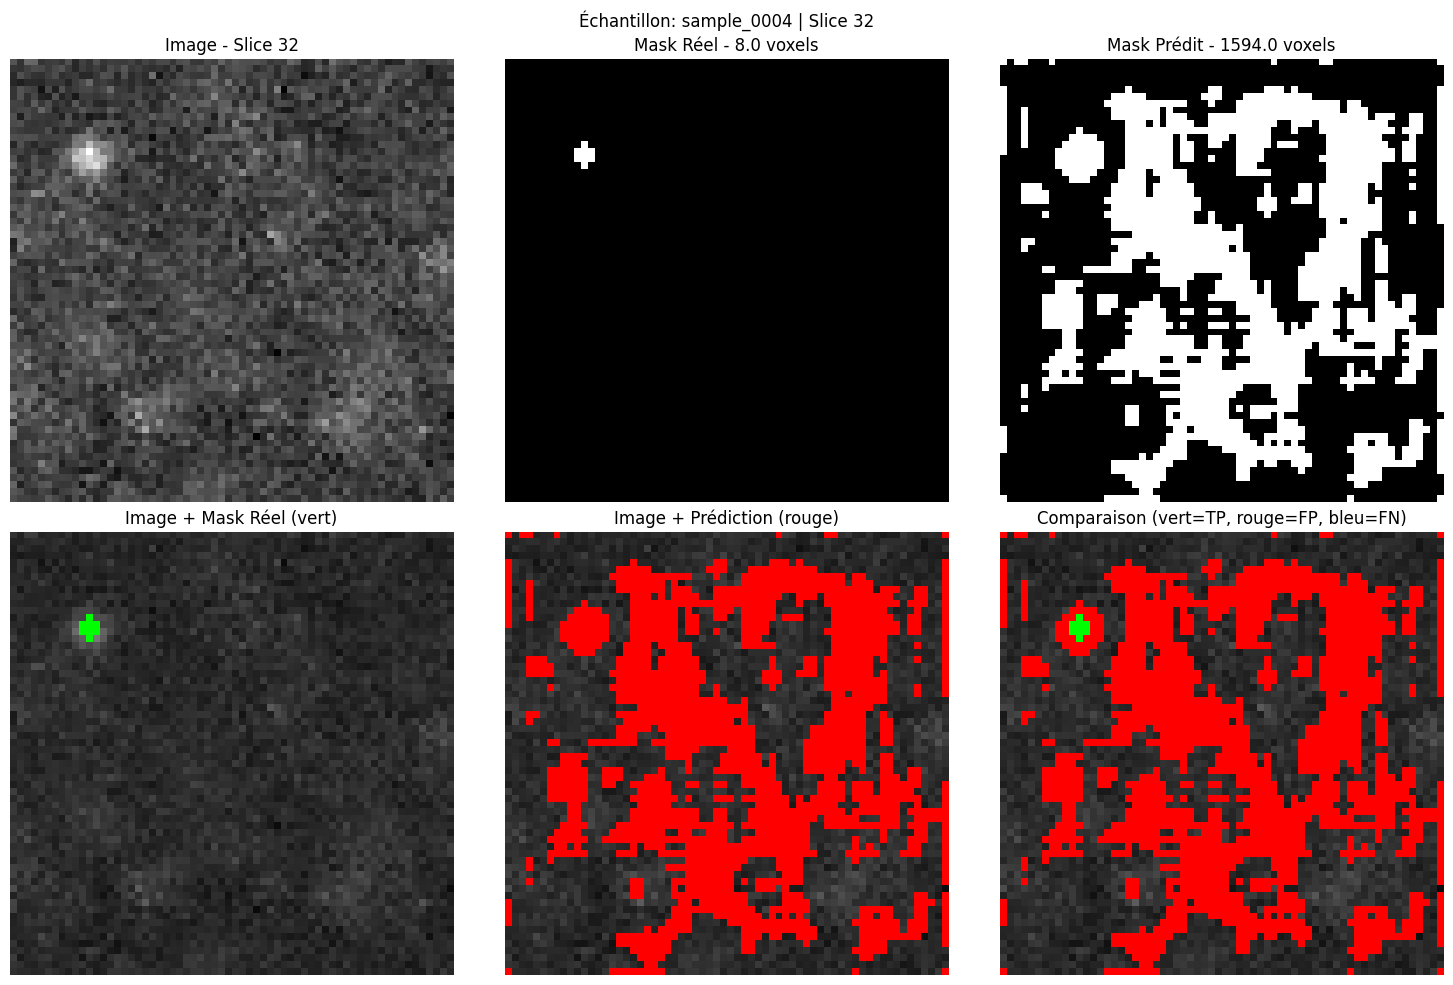

Statistiques de l'échantillon sample_0004:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 674.0
  Voxels neurones (prédit): 81,794
  Taux de détection: 121.36x

Échantillon 6: sample_0005


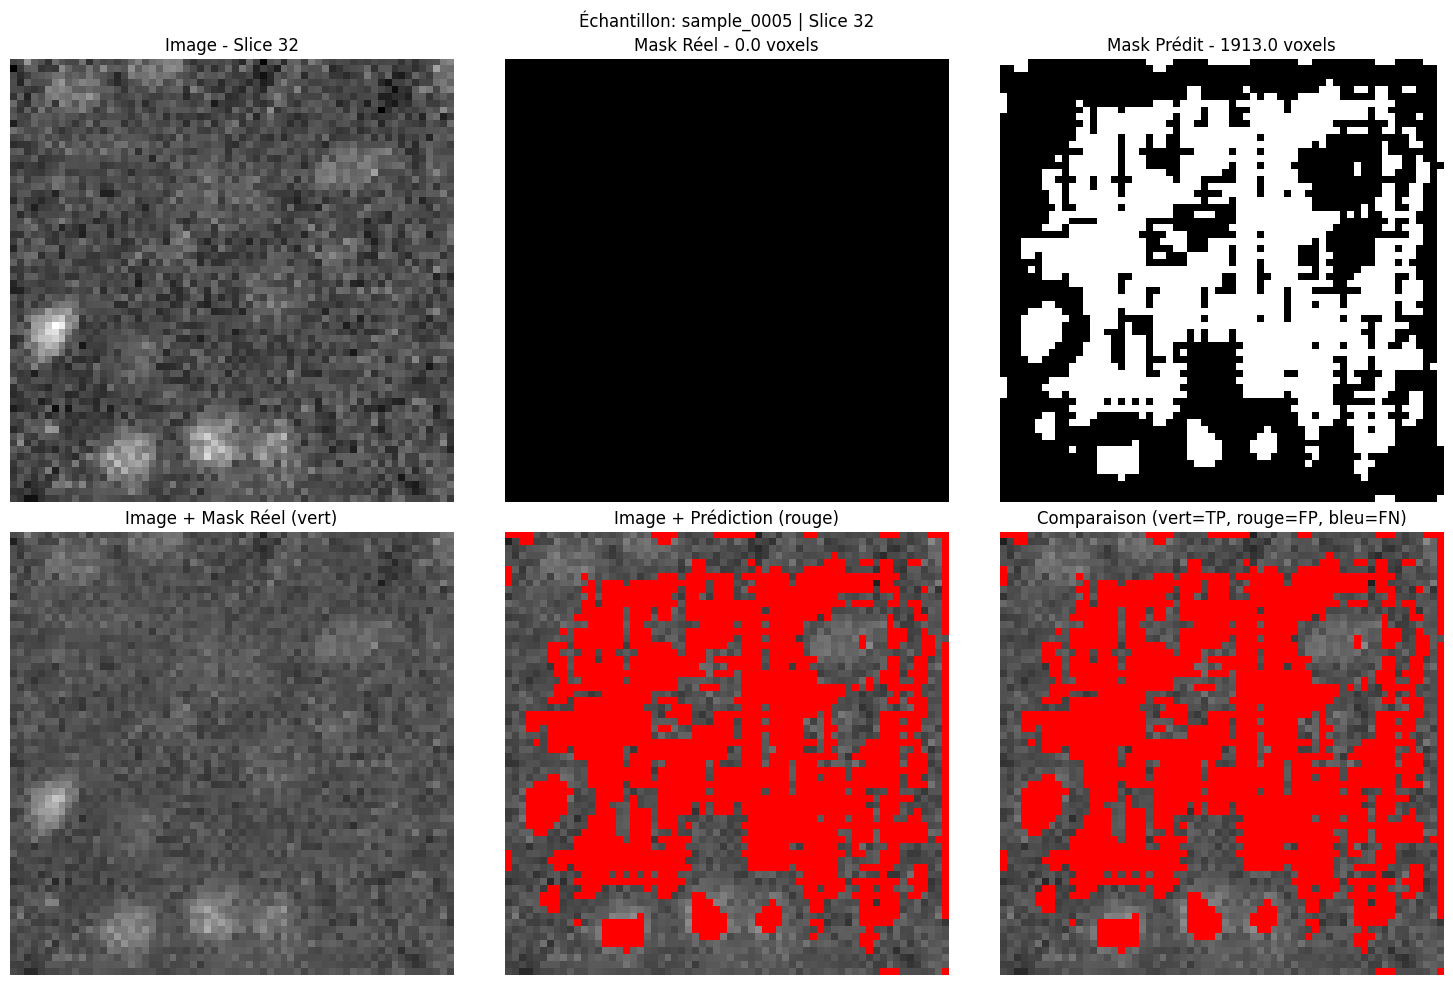

Statistiques de l'échantillon sample_0005:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 25.0
  Voxels neurones (prédit): 77,981
  Taux de détection: 3119.24x


In [6]:
for i, pred_file in enumerate(pred_files[:6]):
    sample_data = np.load(pred_file)
    sample_name = pred_file.stem
    print(f"\n{'='*60}")
    print(f"Échantillon {i+1}: {sample_name}")
    print(f"{'='*60}")
    visualize_prediction(sample_data, sample_name)




Visualisation de l'échantillon sample_0000 sur plusieurs slices


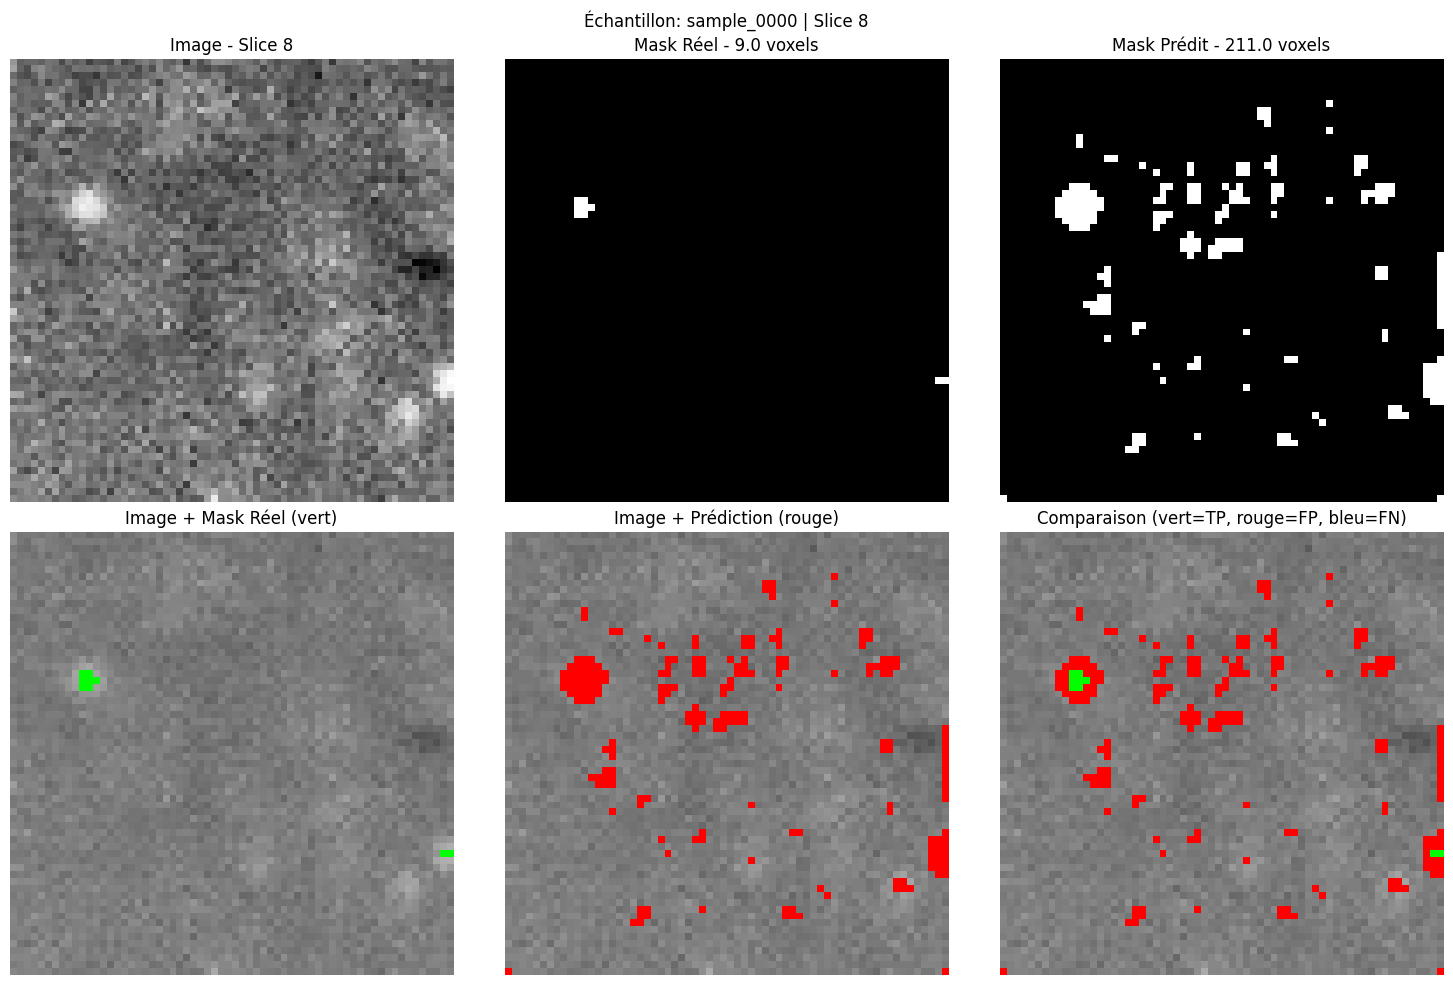

Statistiques de l'échantillon sample_0000:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 242.0
  Voxels neurones (prédit): 14,586
  Taux de détection: 60.27x


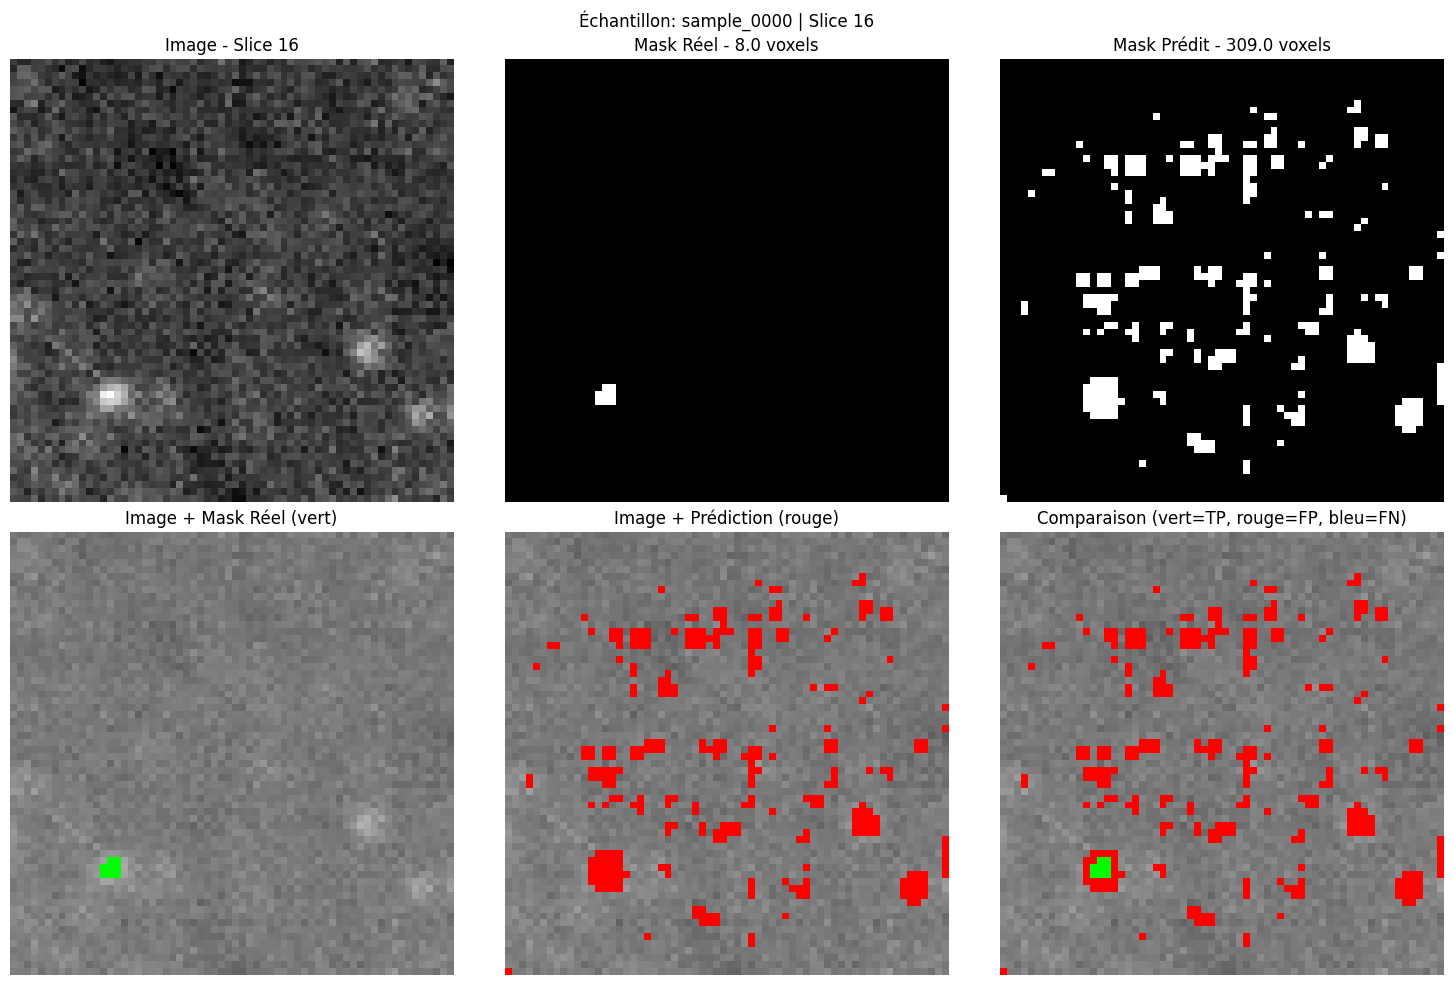

Statistiques de l'échantillon sample_0000:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 242.0
  Voxels neurones (prédit): 14,586
  Taux de détection: 60.27x


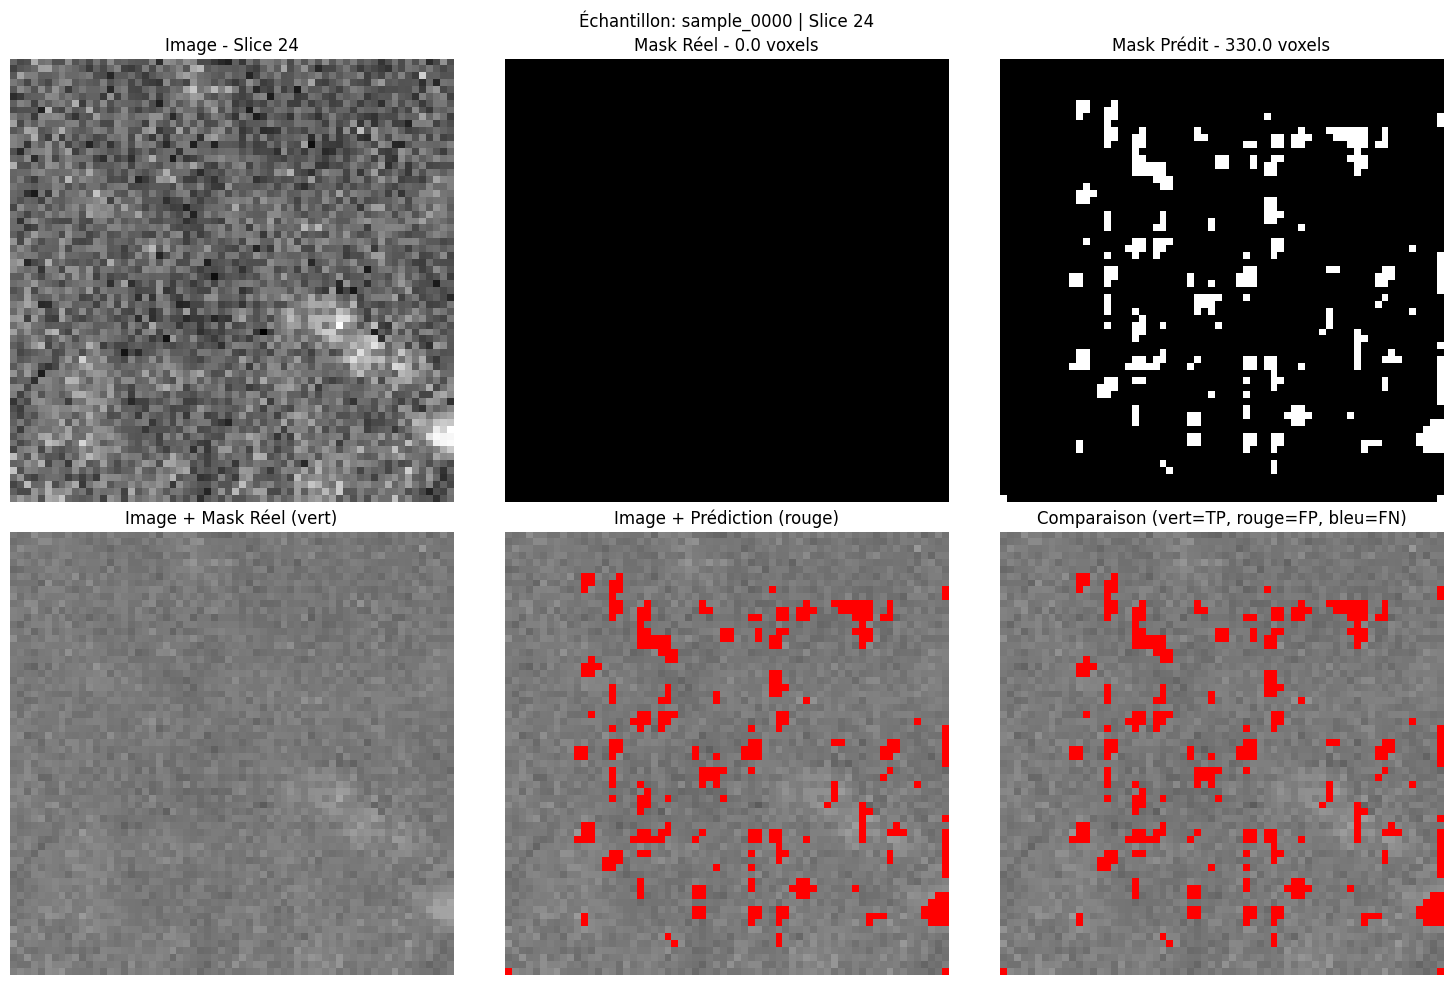

Statistiques de l'échantillon sample_0000:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 242.0
  Voxels neurones (prédit): 14,586
  Taux de détection: 60.27x


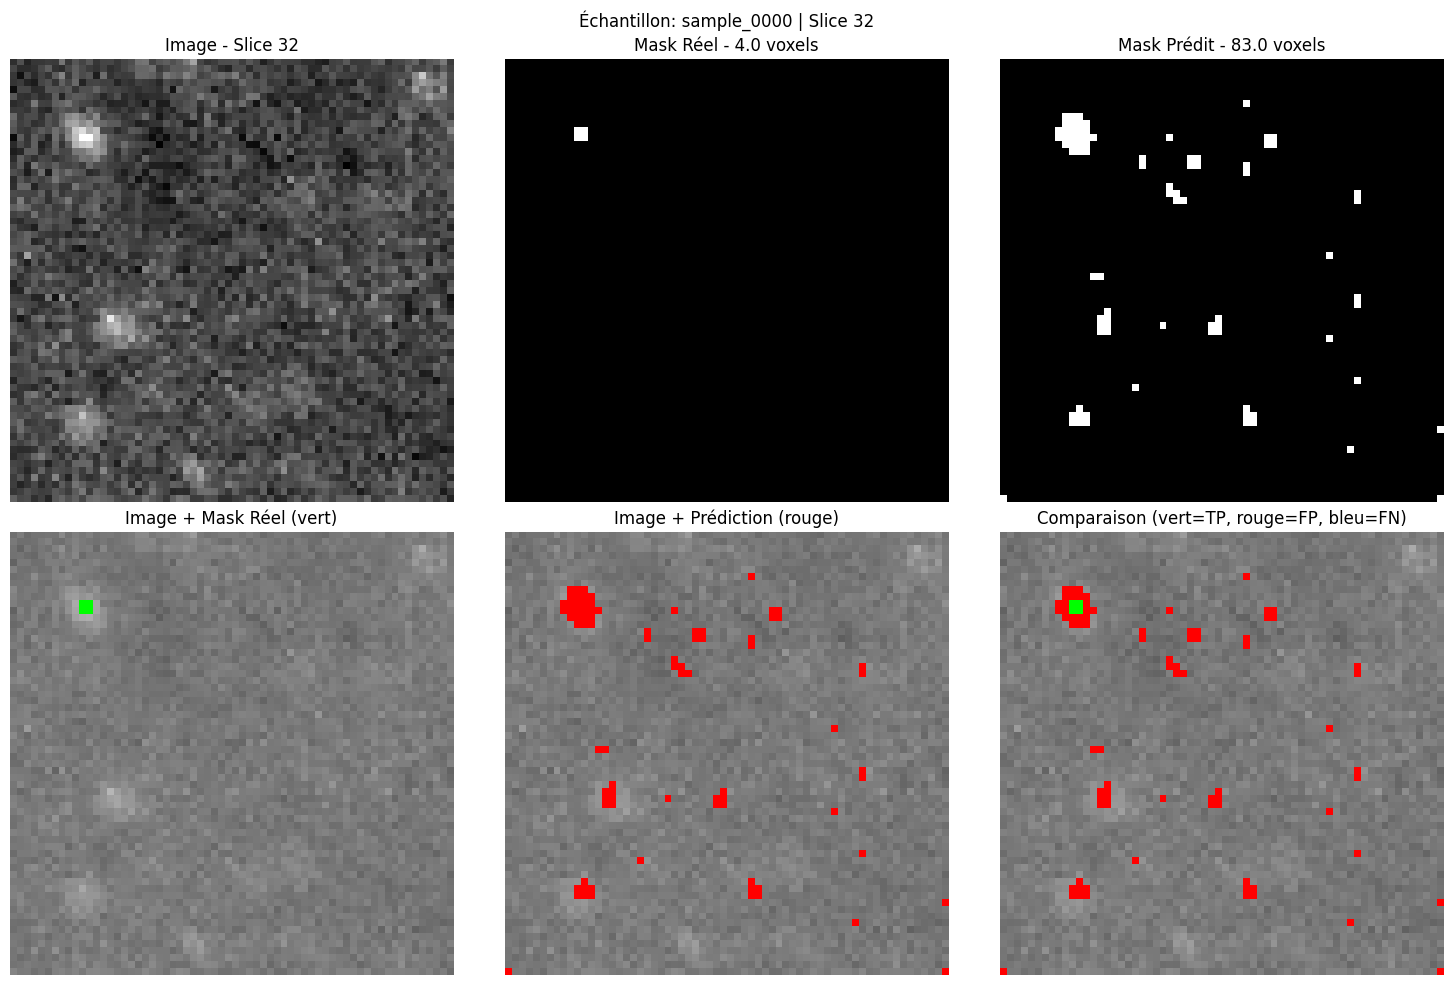

Statistiques de l'échantillon sample_0000:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 242.0
  Voxels neurones (prédit): 14,586
  Taux de détection: 60.27x


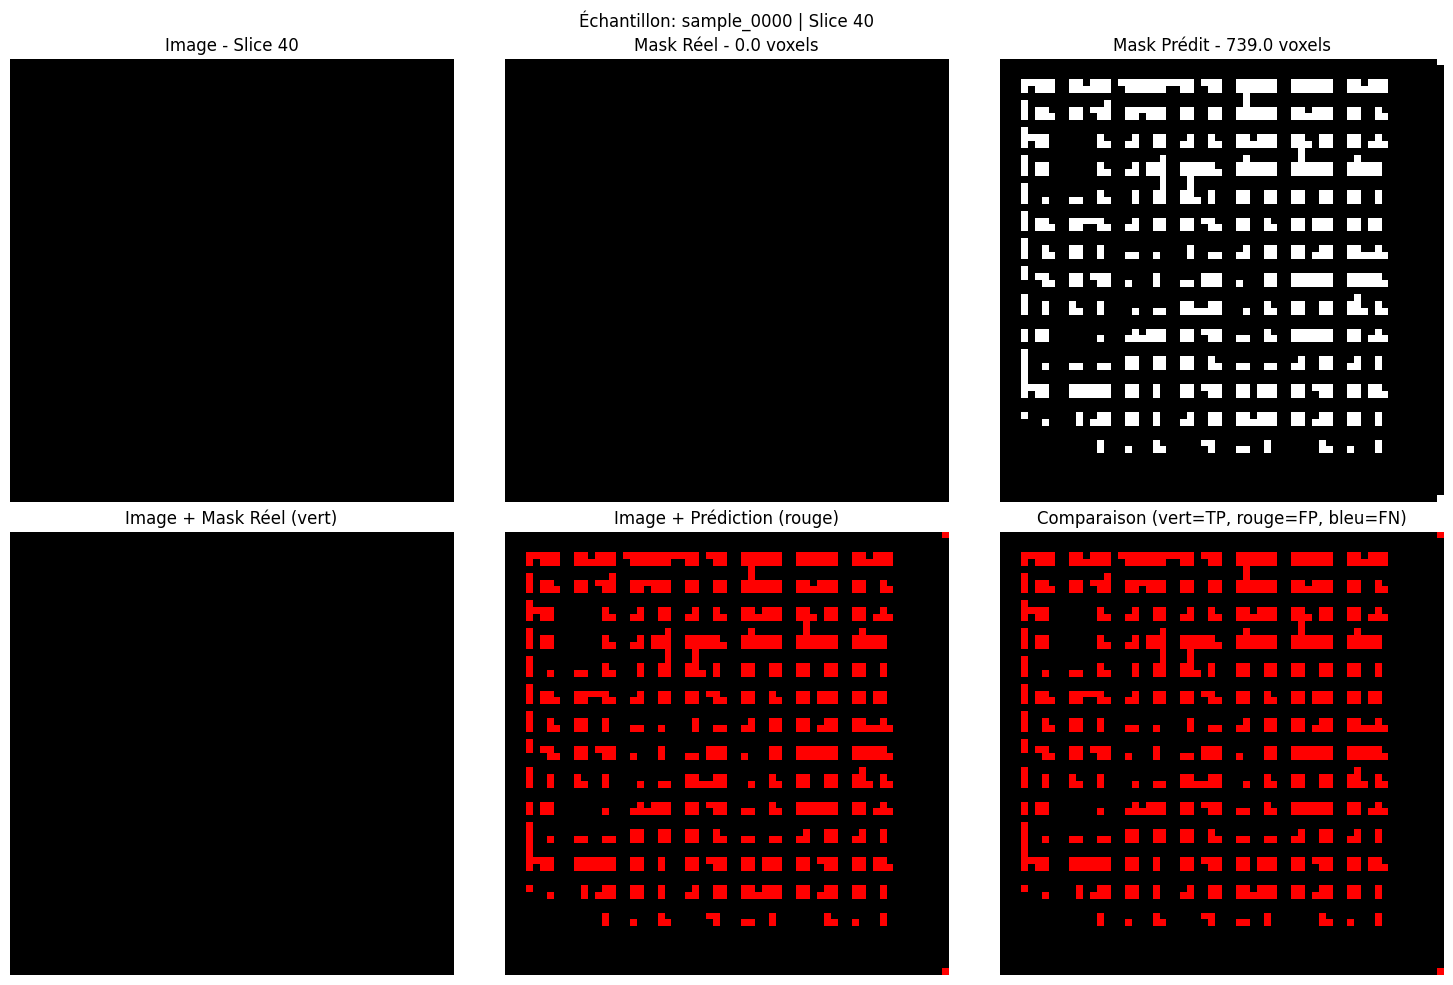

Statistiques de l'échantillon sample_0000:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 242.0
  Voxels neurones (prédit): 14,586
  Taux de détection: 60.27x


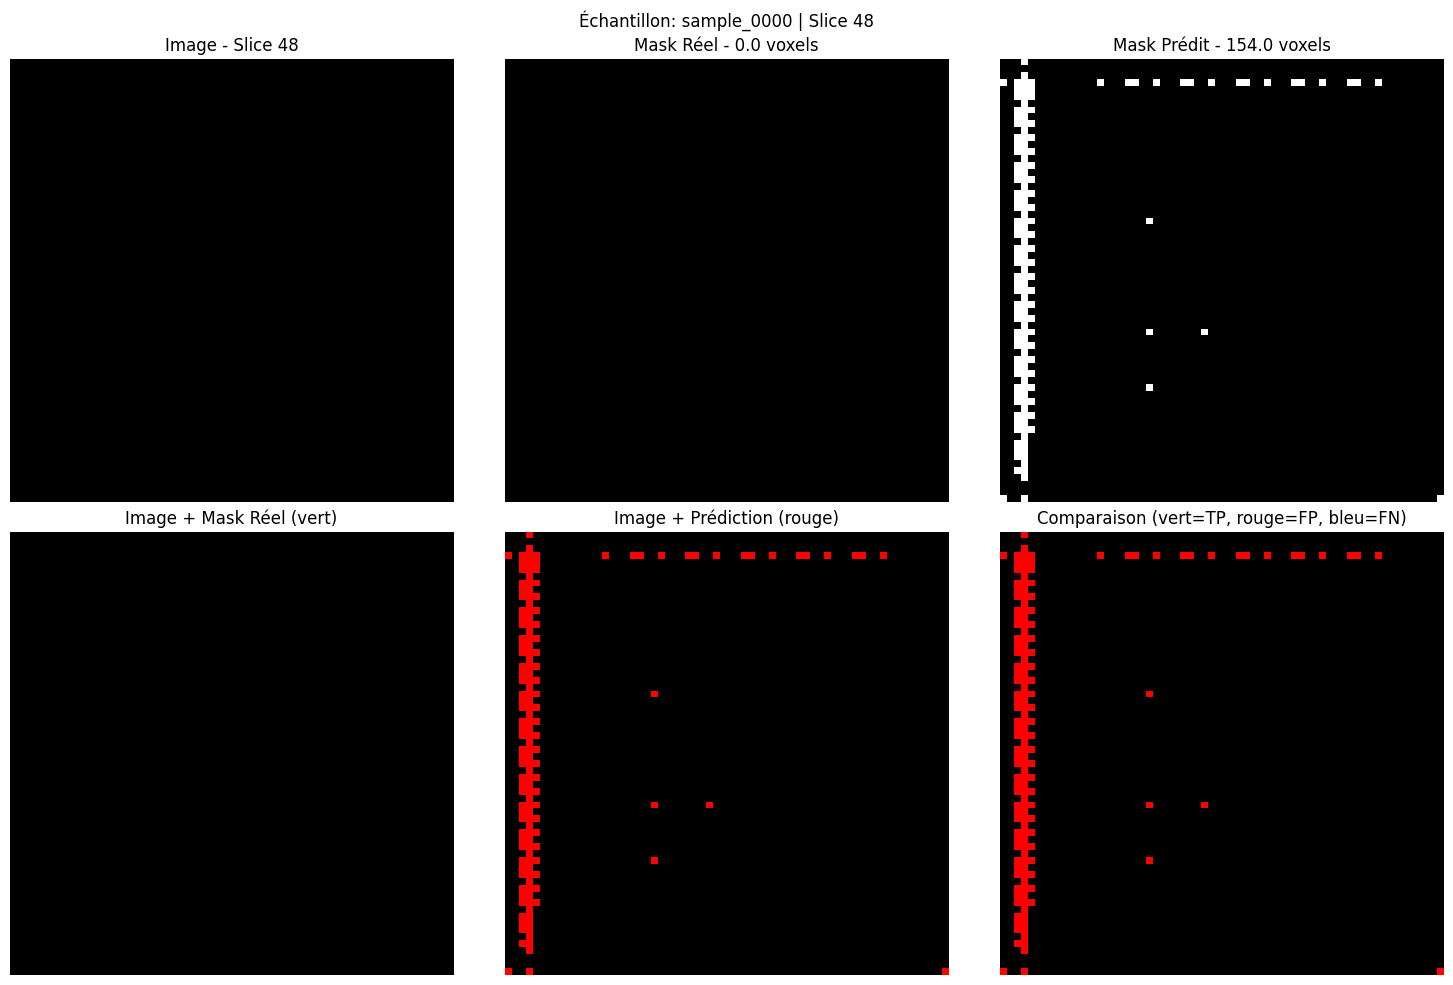

Statistiques de l'échantillon sample_0000:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 242.0
  Voxels neurones (prédit): 14,586
  Taux de détection: 60.27x


In [7]:
# Cell 6: Voir les prédictions sur plusieurs slices du même échantillon
sample_idx = 0
sample_data = np.load(pred_files[sample_idx])
sample_name = pred_files[sample_idx].stem

print(f"\n{'='*60}")
print(f"Visualisation de l'échantillon {sample_name} sur plusieurs slices")
print(f"{'='*60}")

slices = [8, 16, 24, 32, 40, 48]
for slice_idx in slices:
    visualize_prediction(sample_data, sample_name, slice_index=slice_idx)



In [8]:
# Cell 7: Statistiques sur toutes les prédictions
def compute_prediction_stats(pred_files):
    """
    Calcule des statistiques sur toutes les prédictions
    """
    all_neurons_real = []
    all_neurons_pred = []
    
    for pred_file in pred_files:
        sample = np.load(pred_file)
        mask = sample["mask"]
        pred = sample["prediction"]
        
        pred_bin = (pred > 0.5).astype(np.float32)
        
        all_neurons_real.append(mask.sum())
        all_neurons_pred.append(pred_bin.sum())
    
    return np.array(all_neurons_real), np.array(all_neurons_pred)

real, pred = compute_prediction_stats(pred_files)

print("\n" + "=" * 60)
print("STATISTIQUES GLOBALES SUR LES PRÉDICTIONS")
print("=" * 60)
print(f"Nombre d'échantillons: {len(real)}")
print(f"Neurones réels - min: {real.min():,}, max: {real.max():,}, moyenne: {real.mean():.2f}")
print(f"Neurones prédits - min: {pred.min():,}, max: {pred.max():,}, moyenne: {pred.mean():.2f}")
print(f"Taux de détection moyen: {pred.mean() / real.mean() if real.mean() > 0 else 0:.2f}x")




STATISTIQUES GLOBALES SUR LES PRÉDICTIONS
Nombre d'échantillons: 20
Neurones réels - min: 0.0, max: 825.0, moyenne: 254.05
Neurones prédits - min: 9,047.0, max: 121,958.0, moyenne: 58318.75
Taux de détection moyen: 229.56x


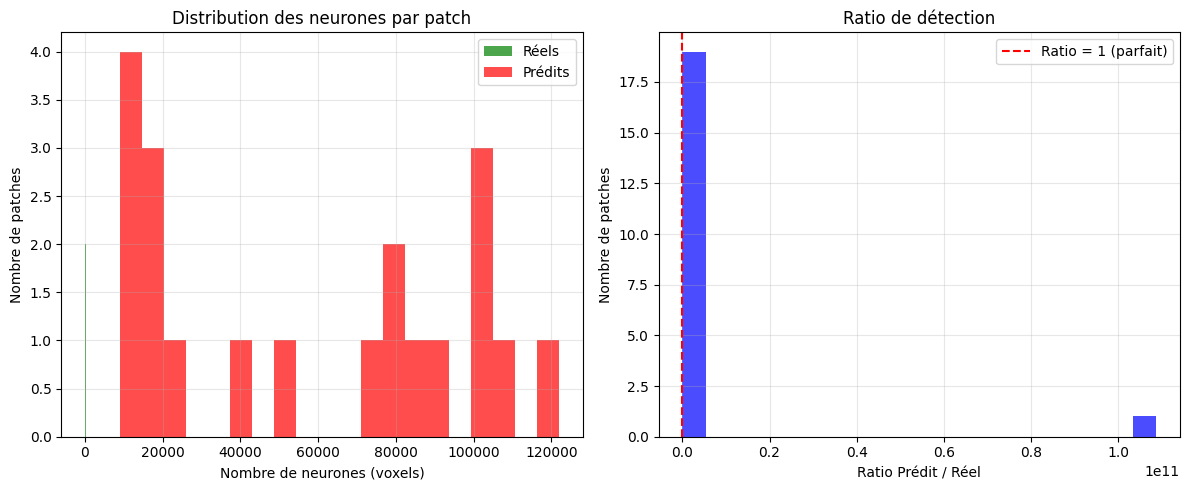

In [9]:
# Cell 8: Histogramme des neurones détectés
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(real[real > 0], bins=20, alpha=0.7, label='Réels', color='green')
plt.hist(pred[pred > 0], bins=20, alpha=0.7, label='Prédits', color='red')
plt.xlabel('Nombre de neurones (voxels)')
plt.ylabel('Nombre de patches')
plt.title('Distribution des neurones par patch')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
ratio = pred / (real + 1e-6)
plt.hist(ratio, bins=20, alpha=0.7, color='blue')
plt.axvline(x=1, color='red', linestyle='--', label='Ratio = 1 (parfait)')
plt.xlabel('Ratio Prédit / Réel')
plt.ylabel('Nombre de patches')
plt.title('Ratio de détection')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()




ÉCHANTILLON LE PLUS PROCHE DE LA RÉALITÉ
Fichier: sample_0014.npz
Réel: 374.0 voxels
Prédit: 13,143.0 voxels
Ratio: 35.14


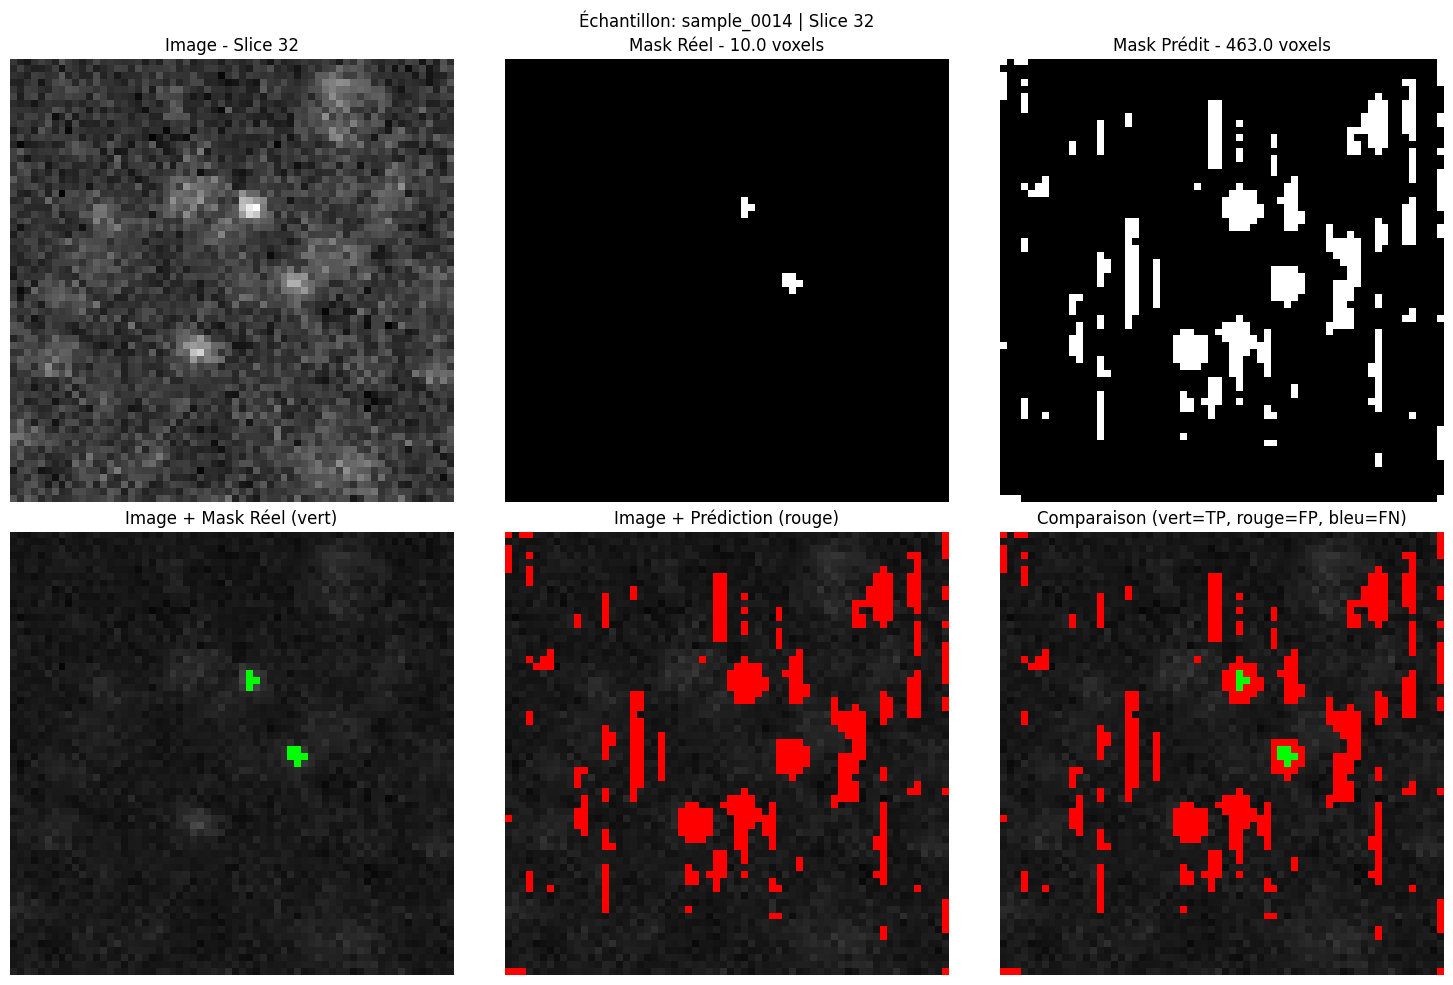

Statistiques de l'échantillon sample_0014:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 374.0
  Voxels neurones (prédit): 13,143
  Taux de détection: 35.14x

ÉCHANTILLON LE PLUS ÉLOIGNÉ DE LA RÉALITÉ
Fichier: sample_0007.npz
Réel: 0.0 voxels
Prédit: 108,692.0 voxels
Ratio: 108691996672.00


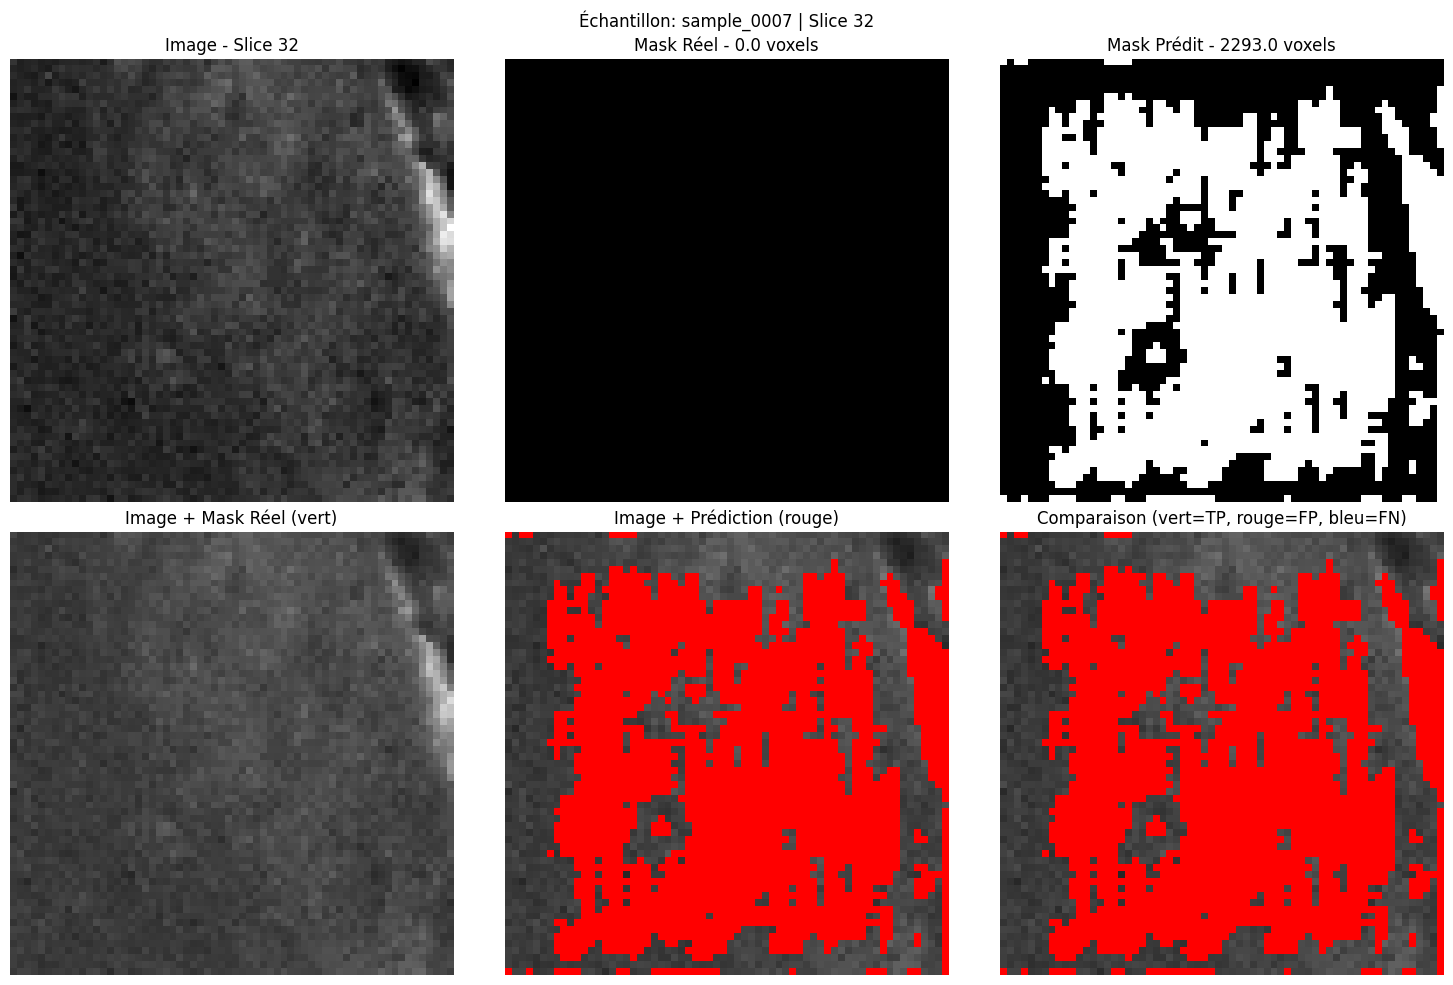

Statistiques de l'échantillon sample_0007:
  Voxels dans l'image: 262,144
  Voxels neurones (réel): 0.0
  Voxels neurones (prédit): 108,692
  Taux de détection: 0.00x


In [10]:
ratios = pred / (real + 1e-6)
best_idx = np.argmin(np.abs(ratios - 1)) 
worst_idx = np.argmax(np.abs(ratios - 1)) 

print(f"\n{'='*60}")
print("ÉCHANTILLON LE PLUS PROCHE DE LA RÉALITÉ")
print(f"{'='*60}")
print(f"Fichier: {pred_files[best_idx].name}")
print(f"Réel: {real[best_idx]:,} voxels")
print(f"Prédit: {pred[best_idx]:,} voxels")
print(f"Ratio: {ratios[best_idx]:.2f}")

sample_best = np.load(pred_files[best_idx])
visualize_prediction(sample_best, pred_files[best_idx].stem)

print(f"\n{'='*60}")
print("ÉCHANTILLON LE PLUS ÉLOIGNÉ DE LA RÉALITÉ")
print(f"{'='*60}")
print(f"Fichier: {pred_files[worst_idx].name}")
print(f"Réel: {real[worst_idx]:,} voxels")
print(f"Prédit: {pred[worst_idx]:,} voxels")
print(f"Ratio: {ratios[worst_idx]:.2f}")

sample_worst = np.load(pred_files[worst_idx])
visualize_prediction(sample_worst, pred_files[worst_idx].stem)